# Ukraine Air Raid Alerts: Model Training & Evaluation Pipeline
> **Implementation aligned with PLAN.md (Phase 1 MVP)**
>
> **Task A (Active Alert):** Predict remaining duration ($P10, P50, P90$) and probability of alert ending within 15 / 30 / 60 minutes given elapsed time $t$.
>
> **Task B (Quiet Region):** Predict time until next alert ($P10, P50, P90$) and probability of alert starting within 1 / 3 / 6 hours given quiet elapsed time $t_{quiet}$.
>
> *Disclaimer: Statistical experiment for research and analysis. Never replaces official alert sirens or civil defense alerts.*


## 1. Setup & Imports


In [1]:
%load_ext autoreload
%autoreload 2

import sys
import os
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Add src to python path
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root / "src"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from lifelines import KaplanMeierFitter

# Import project modules
from alertpred.config import (
    RAW_DATA_PATH,
    MODELS_DIR,
    PROCESSED_DATA_DIR,
    REGION_MAPPING,
    OBLAST_NEIGHBORS,
    TASK_A_HORIZONS_MIN,
    TASK_B_HORIZONS_MIN,
)
from alertpred.data.cleaning import (
    load_raw_data,
    clean_alerts,
    build_oblast_rollup_episodes,
    load_and_clean_volunteer_data,
    build_gap_episodes,
    create_time_split,
)
from alertpred.ingestion.alerts_client import get_api_token
from alertpred.ingestion.backfill import fetch_all_region_histories, merge_with_existing
from alertpred.ingestion.live import get_live_alerts_status
from alertpred.features.builder import (
    sample_as_of_alert_moments,
    sample_as_of_gap_moments,
)
from alertpred.models.baseline import (
    EmpiricalConditionalBaseline,
    KaplanMeierBaseline,
)
from alertpred.models.quantile_lgbm import (
    LightGBMQuantileModel,
    LightGBMProbabilityModel,
    AlertPredictionPipeline,
)
from alertpred.evaluation.metrics import (
    evaluate_quantile_predictions,
    evaluate_classification_probabilities,
)

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

print(f"Project root: {project_root}")
print(f"Raw data path: {RAW_DATA_PATH} (exists: {RAW_DATA_PATH.exists()})")


Project root: /Users/allakovalcuk/Agentic_AI
Raw data path: /Users/allakovalcuk/Agentic_AI/data/raw/official_data_uk.csv (exists: True)


## 2. Data Ingestion & Cleaning
Per **PLAN.md Section 3.4**: parse timestamps to UTC, drop technical
glitches (< 1 minute) and unbounded anomalies, deduplicate overlapping
intervals, map Ukrainian oblast names to standardized IDs.

What's *not* a simple filter: oblast-level forecasting needs oblast-level
episodes, but as section 2.1b shows, a naive `level == 'oblast'` filter
badly under-counts recent activity, because reporting granularity itself
changed partway through the dataset. Section 2.1b fixes that with a
rollup. Sections 2.2-2.4 then backfill the gap up to "now" using the
alerts.in.ua API (affected by the same granularity shift, fixed the same
way) and validate everything before merging into the table the rest of
this notebook uses.


### 2.1 Original Historical Dataset (GitHub)


In [2]:
# Load raw data
df_raw = load_raw_data(RAW_DATA_PATH)
print(f"Total raw records: {len(df_raw):,}")
display(df_raw.head())


Total raw records: 299,275


,oblast,raion,hromada,level,started_at,finished_at,source
0,Вінницька область,NaN,NaN,oblast,2022-03-15 16:10:34+00:00,2022-03-15 16:50:07+00:00,official
1,Житомирська область,NaN,NaN,oblast,2022-03-15 16:11:25+00:00,2022-03-15 16:54:23+00:00,official
2,Черкаська область,Уманський район,Уманська територіальна громада,hromada,2022-03-15 16:11:50+00:00,2022-03-15 16:54:47+00:00,official
3,Миколаївська область,Первомайський район,м. Первомайськ та Первомайська територіальна г...,hromada,2022-03-15 16:14:46+00:00,2022-03-15 16:57:08+00:00,official
4,Кіровоградська область,NaN,NaN,oblast,2022-03-15 16:15:11+00:00,2022-03-15 16:54:52+00:00,official


In [3]:
# Naive cleaning: native oblast-level rows only (kept here to demonstrate
# the bias in 2.1b - NOT used for the rest of the notebook)
df_alerts_naive = clean_alerts(df_raw, filter_level='oblast', min_duration_sec=60)
print(f"Naive oblast-only episodes: {len(df_alerts_naive):,}")
print(f"Date range: {df_alerts_naive['started_at'].min().strftime('%Y-%m-%d')} to {df_alerts_naive['started_at'].max().strftime('%Y-%m-%d')}")


Naive oblast-only episodes: 65,172
Date range: 2022-03-15 to 2026-09-05


### 2.1b The Granularity-Shift Bias, and Fixing It
Ukraine's official alert reporting shifted from oblast-wide blanket alerts
to localized raion/hromada alerts over Aug-Nov 2025 (plotted below). A
`level == 'oblast'` filter treats that shift as "alerts nearly stopped,"
which is false - activity continued, just reported at finer granularity.

`alertpred.data.cleaning.build_oblast_rollup_episodes` fixes this: it uses
*every* row regardless of level, and merges overlapping/touching
raion/hromada alerts within the same oblast into oblast-level episodes
(`alertpred.data.rollup`). Each resulting episode is tagged `level='oblast'`
if built entirely from native oblast-wide rows, or `level='oblast_rollup'`
if it required merging sub-oblast rows - so the derivation stays visible
rather than hidden.


In [4]:
# Bias-corrected cleaning: rolls raion/hromada alerts up to oblast level
df_alerts_github = build_oblast_rollup_episodes(df_raw, min_duration_sec=60)
print(f"Rollup-corrected episodes: {len(df_alerts_github):,}  (naive oblast-only was {len(df_alerts_naive):,})")
print(f"Number of regions: {df_alerts_github['region_id'].nunique()}")
print(f"Date range: {df_alerts_github['started_at'].min().strftime('%Y-%m-%d')} to {df_alerts_github['started_at'].max().strftime('%Y-%m-%d')}")
display(df_alerts_github['level'].value_counts().rename('episodes'))
display(df_alerts_github.head())


Rollup-corrected episodes: 85,579  (naive oblast-only was 65,172)
Number of regions: 24
Date range: 2022-03-15 to 2026-09-07


level
oblast           56430
oblast_rollup    29149
Name: episodes, dtype: int64

,oblast,raion,hromada,level,started_at,finished_at,source,duration_min,region_id,region_en
0,Черкаська область,None,None,oblast_rollup,2022-03-15 16:11:50+00:00,2022-03-15 16:54:47+00:00,official,42.950000,cherkasy,Cherkasy Oblast
1,Черкаська область,None,None,oblast_rollup,2022-03-15 18:04:27+00:00,2022-03-15 18:35:27+00:00,official,31.000000,cherkasy,Cherkasy Oblast
2,Черкаська область,None,None,oblast,2022-03-16 00:50:06+00:00,2022-03-16 04:42:26+00:00,official,232.333333,cherkasy,Cherkasy Oblast
3,Черкаська область,None,None,oblast_rollup,2022-03-16 09:47:38+00:00,2022-03-16 10:45:26+00:00,official,57.800000,cherkasy,Cherkasy Oblast
4,Черкаська область,None,None,oblast_rollup,2022-03-16 11:35:15+00:00,2022-03-16 13:12:46+00:00,official,97.516667,cherkasy,Cherkasy Oblast


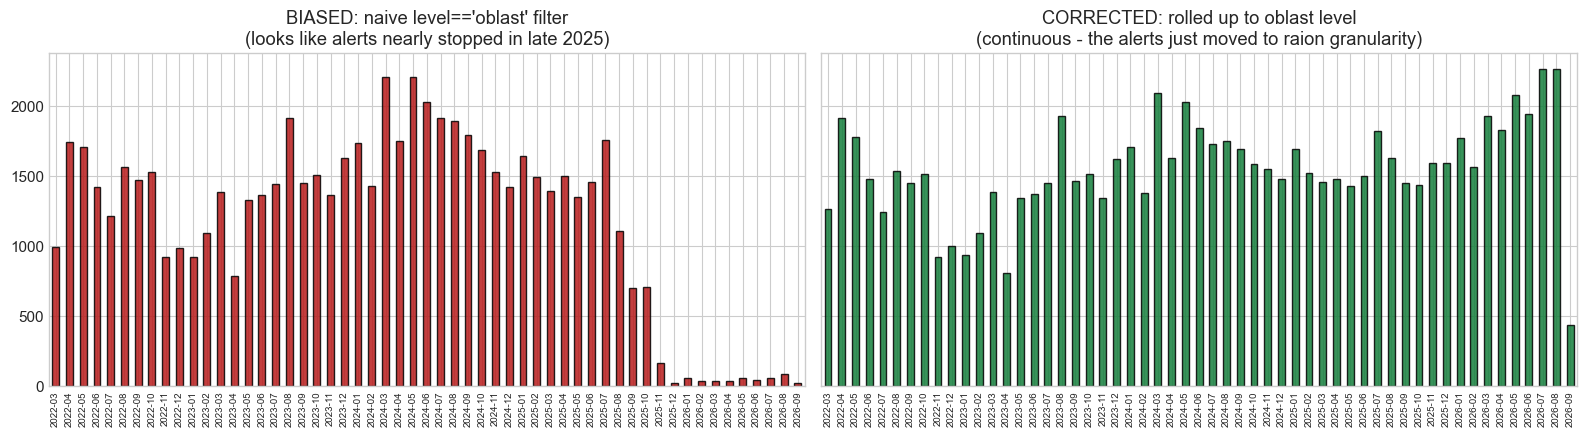

Rollup composition in the most recent 6 months (share built from sub-oblast rows):


level
oblast_rollup    97.2
oblast            2.8
Name: pct, dtype: float64

In [5]:
# The bias, visualized: naive monthly volume (looks like alerts collapsed)
# vs. rollup-corrected monthly volume (continuous, because they didn't)
naive_monthly = df_alerts_naive.set_index('started_at').resample('ME').size()
rollup_monthly = df_alerts_github.set_index('started_at').resample('ME').size()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
naive_monthly.plot(kind='bar', ax=axes[0], color='#b91c1c', edgecolor='black', alpha=0.85)
axes[0].set_title("BIASED: naive level=='oblast' filter\n(looks like alerts nearly stopped in late 2025)")
axes[0].set_xlabel("")
axes[0].set_xticklabels([t.get_text()[:7] for t in axes[0].get_xticklabels()], rotation=90, fontsize=7)

rollup_monthly.plot(kind='bar', ax=axes[1], color='#15803d', edgecolor='black', alpha=0.85)
axes[1].set_title("CORRECTED: rolled up to oblast level\n(continuous - the alerts just moved to raion granularity)")
axes[1].set_xlabel("")
axes[1].set_xticklabels([t.get_text()[:7] for t in axes[1].get_xticklabels()], rotation=90, fontsize=7)

plt.tight_layout()
plt.show()

print("Rollup composition in the most recent 6 months (share built from sub-oblast rows):")
recent = df_alerts_github[df_alerts_github['started_at'] >= df_alerts_github['started_at'].max() - pd.Timedelta(days=180)]
display((recent['level'].value_counts(normalize=True) * 100).round(1).rename('pct'))


### 2.2 Backfilling Recent Data via the alerts.in.ua API
[devs.alerts.in.ua](https://devs.alerts.in.ua/) exposes `/v1/regions/{uid}/alerts/month_ago.json`,
a rolling ~30-day history per oblast. We fetch it for all 27 oblasts and
reshape it into the same rollup episode schema as 2.1b (alerts.in.ua is
*also* almost entirely raion-level now - a naive oblast-type filter here
would return close to nothing for every oblast except Kyiv city) so the two
sources can be concatenated.

**Caching & rate limits (per the docs):** this endpoint is limited to
2 requests/minute. `alertpred.ingestion.alerts_client` caches every response
to `data/cache/alerts_in_ua/` on disk and sends `If-Modified-Since` on
repeat calls, so **re-running this cell after the first time costs nothing**.
A cold run across all 27 oblasts takes roughly 13-14 minutes.

**Known limitation:** `month_ago` is the only documented lookback window -
it cannot reach further back than ~30 days. If the GitHub dataset's tail is
older than that, a gap will remain between the two sources (reported in 2.3).

Requires `ALERTS_IN_UA_TOKEN` in the environment or a `.env` file (copy
`.env.example` -> `.env` and fill in a token requested at the link above).
Without a token this cell is skipped and the notebook continues with the
GitHub-only dataset.


In [6]:
# Fetch per-oblast history from alerts.in.ua (or skip gracefully if no token is configured)
api_token = get_api_token()

if not api_token:
    print("No ALERTS_IN_UA_TOKEN found (env var or .env file).")
    print("Skipping the API backfill - continuing with the GitHub historical dataset only.")
    print("To enable: copy .env.example to .env and set your token (request one at https://devs.alerts.in.ua/).")
    df_alerts_api = pd.DataFrame()
else:
    print("Token found. Fetching ~last 30 days of history per oblast from alerts.in.ua")
    print("(cached on disk - a cold run takes ~13-14 min due to the API's 2 req/min history limit)\n")
    df_alerts_api = fetch_all_region_histories(period='month_ago')
    n_regions = df_alerts_api['region_id'].nunique() if not df_alerts_api.empty else 0
    print(f"\nFetched {len(df_alerts_api):,} completed episodes across {n_regions} regions from alerts.in.ua")
    if not df_alerts_api.empty:
        display(df_alerts_api.head())


Token found. Fetching ~last 30 days of history per oblast from alerts.in.ua
(cached on disk - a cold run takes ~13-14 min due to the API's 2 req/min history limit)

  [1/27] khmelnytskyi (uid=3): 107 completed episodes


  [2/27] vinnytsia (uid=4): 146 completed episodes


  [3/27] rivne (uid=5): 128 completed episodes
  [4/27] volyn (uid=8): 67 completed episodes


  [5/27] dnipropetrovsk (uid=9): 42 completed episodes (3 dropped, >72h merged chain)
  [6/27] zhytomyr (uid=10): 231 completed episodes
  [7/27] zakarpattia (uid=11): 3 completed episodes


  [8/27] zaporizhzhia (uid=12): 159 completed episodes
  [9/27] ivano_frankivsk (uid=13): 16 completed episodes


...

  [18/27] kharkiv (uid=22): 224 completed episodes
  [19/27] kherson (uid=23): 258 completed episodes


  [20/27] cherkasy (uid=24): 229 completed episodes
  [21/27] chernihiv (uid=25): 189 completed episodes


  [22/27] chernivtsi (uid=26): 34 completed episodes
  [23/27] lviv (uid=27): 18 completed episodes
  [24/27] donetsk (uid=28): 59 completed episodes
  [25/27] crimea (uid=29): 0 completed episodes
  [26/27] sevastopol (uid=30): 0 completed episodes


  [27/27] kyiv_city (uid=31): 218 completed episodes

Fetched 3,904 completed episodes across 24 regions from alerts.in.ua


,oblast,raion,hromada,level,started_at,finished_at,source,duration_min,region_id,region_en
0,Черкаська область,None,None,oblast_rollup,2026-09-12 12:26:21.818000+00:00,2026-09-12 17:53:43+00:00,alerts_in_ua,327.353033,cherkasy,Cherkasy Oblast
1,Черкаська область,None,None,oblast_rollup,2026-09-12 18:53:17.543000+00:00,2026-09-12 21:40:12+00:00,alerts_in_ua,166.907617,cherkasy,Cherkasy Oblast
2,Черкаська область,None,None,oblast_rollup,2026-09-13 06:20:28.154000+00:00,2026-09-13 09:44:48+00:00,alerts_in_ua,204.330767,cherkasy,Cherkasy Oblast
3,Черкаська область,None,None,oblast_rollup,2026-09-13 14:08:34.780000+00:00,2026-09-13 14:54:08+00:00,alerts_in_ua,45.553667,cherkasy,Cherkasy Oblast
4,Черкаська область,None,None,oblast_rollup,2026-09-13 19:16:21.448000+00:00,2026-09-13 20:26:14+00:00,alerts_in_ua,69.875867,cherkasy,Cherkasy Oblast


### 2.3 Validating the Backfilled Data
Before trusting the new source, sanity-check it against the GitHub dataset:
coverage (does it actually close the gap?), any remaining uncovered gap,
rollup composition (native vs. derived), and whether duration distributions
are in the same ballpark (a large divergence would indicate a parsing or
schema mismatch, not a real behavioral shift).


In [7]:
if df_alerts_api.empty:
    print("No API data fetched - nothing to validate.")
else:
    print(f"GitHub dataset date range  : {df_alerts_github['started_at'].min().strftime('%Y-%m-%d %H:%M')} to {df_alerts_github['started_at'].max().strftime('%Y-%m-%d %H:%M')}")
    print(f"alerts.in.ua date range    : {df_alerts_api['started_at'].min().strftime('%Y-%m-%d %H:%M')} to {df_alerts_api['started_at'].max().strftime('%Y-%m-%d %H:%M')}")

    gh_end = df_alerts_github['started_at'].max()
    api_start = df_alerts_api['started_at'].min()
    if api_start > gh_end:
        print(f"\nWARNING: uncovered gap between the two sources: {gh_end} to {api_start} ({(api_start - gh_end)})")
        print("(alerts.in.ua's history endpoint only exposes a rolling ~30-day window - see 2.2)")
    else:
        print(f"\nSources overlap by {gh_end - api_start} - the merge step (2.4) de-duplicates this overlap.")

    print("\nalerts.in.ua rollup composition (native oblast-wide vs. derived from raion/hromada):")
    display((df_alerts_api['level'].value_counts(normalize=True) * 100).round(1).rename('pct'))

    # Duration sanity check: distributions should be broadly comparable across sources
    compare = pd.concat([
        df_alerts_github.assign(_source='github')[['_source', 'duration_min']],
        df_alerts_api.assign(_source='alerts_in_ua')[['_source', 'duration_min']],
    ])
    print("\nDuration (minutes) by source, oblast-level episodes:")
    display(compare.groupby('_source')['duration_min'].describe().round(1))

    print("\nNew episodes per region (alerts.in.ua backfill):")
    display(df_alerts_api.groupby('region_en').size().sort_values(ascending=False).rename('new_episodes'))


GitHub dataset date range  : 2022-03-15 16:10 to 2026-09-07 04:38
alerts.in.ua date range    : 2026-09-12 02:20 to 2026-10-12 12:39

(alerts.in.ua's history endpoint only exposes a rolling ~30-day window - see 2.2)

alerts.in.ua rollup composition (native oblast-wide vs. derived from raion/hromada):


level
oblast_rollup    94.4
oblast            5.6
Name: pct, dtype: float64


Duration (minutes) by source, oblast-level episodes:


,count,mean,std,min,25%,50%,75%,max
_source,,,,,,,,
alerts_in_ua,3904.0,102.1,186.0,0.3,24.9,46.2,102.0,4204.0
github,85579.0,109.6,198.8,1.0,26.8,45.5,108.5,4290.0



New episodes per region (alerts.in.ua backfill):


region_en
Mykolaiv Oblast           377
Odesa Oblast              343
Sumy Oblast               265
Kherson Oblast            258
Kirovohrad Oblast         251
Poltava Oblast            249
Kyiv Oblast               241
Zhytomyr Oblast           231
Cherkasy Oblast           229
Kharkiv Oblast            224
Kyiv City                 218
Chernihiv Oblast          189
Zaporizhzhia Oblast       159
Vinnytsia Oblast          146
Rivne Oblast              128
Khmelnytskyi Oblast       107
Volyn Oblast               67
Donetsk Oblast             59
Ternopil Oblast            50
Dnipropetrovsk Oblast      42
Chernivtsi Oblast          34
Lviv Oblast                18
Ivano-Frankivsk Oblast     16
Zakarpattia Oblast          3
Name: new_episodes, dtype: int64

### 2.3b A Third Source for the Remaining Gap: the Volunteer Dataset
Even after the API backfill, section 2.3 found a real uncovered gap between
the GitHub CSV's last record and alerts.in.ua's earliest one. The same
GitHub repo also publishes `volunteer_data_uk.csv` - independently
collected from the [eTryvoga](https://app.etryvoga.com) Telegram channel,
covering back to Feb 2022.

**Checking it before trusting it** (per the repo's own README caveats):
it only reports oblast-level events, and `naive=True` rows have no real end
time - they're stamped `started_at + 30min` as a placeholder, not measured.
More importantly, cross-checking it against our official-rollup data for an
overlapping month shows it is not a drop-in replacement: for Kharkiv in
August 2026, it reports far more, much shorter episodes that don't even
align in time with the official-rollup ones - a different detection
methodology, not just a different granularity of the same events.
Given that mismatch, it's used *only* to fill the specific date gap left
over after 2.3, not blended across the whole timeline where it would mix
two differently-measured distributions into one.


In [8]:
df_volunteer = load_and_clean_volunteer_data()
print(f"Volunteer dataset: {len(df_volunteer):,} cleaned episodes, {df_volunteer['started_at'].min().strftime('%Y-%m-%d')} to {df_volunteer['started_at'].max().strftime('%Y-%m-%d')}")

# Quality check: compare against the official rollup for an overlapping month,
# same region - do NOT expect these to match if this is a different
# measurement methodology (it isn't just a finer/coarser view of the same events)
check_region, check_month = 'kharkiv', '2026-08'
vol_check = df_volunteer[(df_volunteer['region_id'] == check_region) & (df_volunteer['started_at'].dt.strftime('%Y-%m') == check_month)]
off_check = df_alerts_github[(df_alerts_github['region_id'] == check_region) & (df_alerts_github['started_at'].dt.strftime('%Y-%m') == check_month)]
print(f"\n{check_region}, {check_month} - volunteer: {len(vol_check)} episodes (mean {vol_check['duration_min'].mean():.0f} min) "
      f"vs official-rollup: {len(off_check)} episodes (mean {off_check['duration_min'].mean():.0f} min)")
print("(large disagreement expected and OK here - this is exactly why it's scoped to the gap-fill only, not merged wholesale)")


Volunteer dataset: 108,958 cleaned episodes, 2022-02-25 to 2026-10-12

kharkiv, 2026-08 - volunteer: 475 episodes (mean 20 min) vs official-rollup: 132 episodes (mean 289 min)
(large disagreement expected and OK here - this is exactly why it's scoped to the gap-fill only, not merged wholesale)


In [9]:
# Apply narrowly: only the window the other two sources don't cover
gap_start, gap_end = df_alerts_github['started_at'].max(), df_alerts_api['started_at'].min() if not df_alerts_api.empty else None

if gap_end is not None and gap_end > gap_start:
    df_volunteer_gapfill = df_volunteer[(df_volunteer['started_at'] >= gap_start) & (df_volunteer['started_at'] < gap_end)]
    print(f"Gap window: {gap_start} to {gap_end} ({gap_end - gap_start})")
    print(f"Volunteer episodes available to fill it: {len(df_volunteer_gapfill):,}")
    display(df_volunteer_gapfill.groupby('region_en').size().sort_values(ascending=False).rename('gapfill_episodes').head(10))
else:
    df_volunteer_gapfill = df_volunteer.iloc[0:0]
    print("No gap to fill (or no API data) - skipping.")


Gap window: 2026-09-07 04:38:21+00:00 to 2026-09-12 02:20:09.292000+00:00 (4 days 21:41:48.292000)
Volunteer episodes available to fill it: 578


region_en
Dnipropetrovsk Oblast    98
Kharkiv Oblast           87
Mykolaiv Oblast          52
Odesa Oblast             40
Sumy Oblast              39
Kyiv Oblast              34
Zaporizhzhia Oblast      32
Kirovohrad Oblast        31
Poltava Oblast           25
Chernihiv Oblast         23
Name: gapfill_episodes, dtype: int64

### 2.4 Merging into the Final Alerts Table
Concatenate all three sources and de-duplicate on `(region_id, started_at)` -
the same rule `clean_alerts` uses internally - so an overlapping tail
produces no duplicate episodes. Everything from here on uses this merged
`df_alerts`.


In [10]:
df_alerts = merge_with_existing(df_alerts_github, df_volunteer_gapfill)
df_alerts = merge_with_existing(df_alerts, df_alerts_api)
print(f"Final merged alert episodes: {len(df_alerts):,}  "
      f"(GitHub: {len(df_alerts_github):,}, volunteer gap-fill: {len(df_volunteer_gapfill):,}, alerts.in.ua: {len(df_alerts_api):,})")
print(f"Number of regions: {df_alerts['region_id'].nunique()}")
print(f"Date range: {df_alerts['started_at'].min().strftime('%Y-%m-%d')} to {df_alerts['started_at'].max().strftime('%Y-%m-%d')}")
display(df_alerts['level'].value_counts().rename('episodes'))
display(df_alerts.tail())


Final merged alert episodes: 90,061  (GitHub: 85,579, volunteer gap-fill: 578, alerts.in.ua: 3,904)
Number of regions: 24
Date range: 2022-03-15 to 2026-10-12


level
oblast              56648
oblast_rollup       32835
oblast_volunteer      578
Name: episodes, dtype: int64

,oblast,raion,hromada,level,started_at,finished_at,source,duration_min,region_id,region_en
90056,Житомирська область,None,None,oblast_rollup,2026-10-12 00:10:10.667000+00:00,2026-10-12 00:36:08+00:00,alerts_in_ua,25.955550,zhytomyr,Zhytomyr Oblast
90057,Житомирська область,None,None,oblast_rollup,2026-10-12 01:59:42.094000+00:00,2026-10-12 03:06:57+00:00,alerts_in_ua,67.248433,zhytomyr,Zhytomyr Oblast
90058,Житомирська область,None,None,oblast_rollup,2026-10-12 03:57:18.858000+00:00,2026-10-12 05:53:16+00:00,alerts_in_ua,115.952367,zhytomyr,Zhytomyr Oblast
90059,Житомирська область,None,None,oblast_rollup,2026-10-12 07:10:44.012000+00:00,2026-10-12 07:52:47+00:00,alerts_in_ua,42.049800,zhytomyr,Zhytomyr Oblast
90060,Житомирська область,None,None,oblast_rollup,2026-10-12 08:23:47.587000+00:00,2026-10-12 10:05:21+00:00,alerts_in_ua,101.556883,zhytomyr,Zhytomyr Oblast


In [11]:
# Build Task B Quiet Gap episodes (time between consecutive alerts per region)
df_gaps = build_gap_episodes(df_alerts)
print(f"Quiet gap episodes: {len(df_gaps):,}")
display(df_gaps.head())


Quiet gap episodes: 90,030


,region_id,region_en,gap_start,gap_end,gap_duration_min,prev_alert_duration_min
0,vinnytsia,Vinnytsia Oblast,2022-03-15 16:50:07+00:00,2022-03-15 16:52:30+00:00,2.383333,39.550000
1,zhytomyr,Zhytomyr Oblast,2022-03-15 16:54:23+00:00,2022-03-15 18:08:22+00:00,73.983333,42.966667
2,cherkasy,Cherkasy Oblast,2022-03-15 16:54:47+00:00,2022-03-15 18:04:27+00:00,69.666667,42.950000
3,kirovohrad,Kirovohrad Oblast,2022-03-15 16:54:52+00:00,2022-03-15 18:11:07+00:00,76.250000,39.683333
4,mykolaiv,Mykolaiv Oblast,2022-03-15 16:57:08+00:00,2022-03-16 00:17:27+00:00,440.316667,42.366667


### 2.5 Live Status Check (Current Information)
Demonstrates `get_live_alerts_status`, which now parses the real
`/v1/alerts/active.json` endpoint (real elapsed minutes per active region)
instead of the old placeholder values, and uses the merged table above to
compute real elapsed-quiet time for regions with no active alert. Falls
back to a demo snapshot if no token is configured or the API is
unreachable.


In [12]:
last_end_by_region = df_alerts.groupby('region_id')['finished_at'].max().to_dict()
live_status = get_live_alerts_status(last_alert_end_by_region=last_end_by_region)

print(f"Mode: {'Live API' if live_status['is_live_api'] else 'Demo Simulation (no token / API unreachable)'}")
print(f"Last updated: {live_status['last_updated']}")
print(f"Active regions: {live_status['total_active_regions']} / {len(live_status['regions'])}")

live_df = pd.DataFrame(live_status['regions']).T
display(live_df.sort_values('is_active', ascending=False))


Mode: Live API
Last updated: 2026-10-12 16:29:04 (Kyiv Time)
Active regions: 10 / 27


,is_active,elapsed_min,elapsed_quiet_min
luhansk,True,2378683.426009,0.0
zhytomyr,True,8.800992,0.0
kharkiv,True,199.958392,0.0
dnipropetrovsk,True,711.024642,0.0
donetsk,True,949.964159,0.0
zaporizhzhia,True,803.257242,0.0
mykolaiv,True,33.898575,0.0
crimea,True,2018347.076009,0.0
chernihiv,True,417.639459,0.0
kyiv,True,80.851109,0.0


## 3. Exploratory Data Analysis (EDA)
Comprehensive exploration of:
1. **Alert Frequency Across Oblasts:** Ranking, volume share, and monthly temporal intensity.
2. **Alert Duration Distributions (Mean vs. Median):** Skewness, dispersion, and diurnal hourly patterns.
3. **Spatial Context & Neighbor Co-Occurrence:** Simultaneous alert rates among direct neighbors, pairwise correlation heatmap, and propagation trajectory analysis.
4. **Quiet Gaps (Task B):** Inter-arrival quiet durations across frontline vs. rear oblasts.


,region_en,total_alerts,alerts_per_month,alerts_per_week,pct_national
0,Kharkiv Oblast,9132,166.255783,38.235416,10.139794
1,Zaporizhzhia Oblast,8477,154.330954,35.492950,9.412509
2,Donetsk Oblast,7598,138.328016,31.812603,8.436504
3,Sumy Oblast,6403,116.572030,26.809173,7.109626
4,Poltava Oblast,6179,112.493921,25.871292,6.860905
5,Mykolaiv Oblast,5927,107.906048,24.816175,6.581095
6,Kherson Oblast,5495,100.041122,23.007404,6.101420
7,Dnipropetrovsk Oblast,5286,96.236100,22.132327,5.869355
8,Kirovohrad Oblast,4878,88.808115,20.424043,5.416329
9,Odesa Oblast,4432,80.688308,18.556654,4.921109


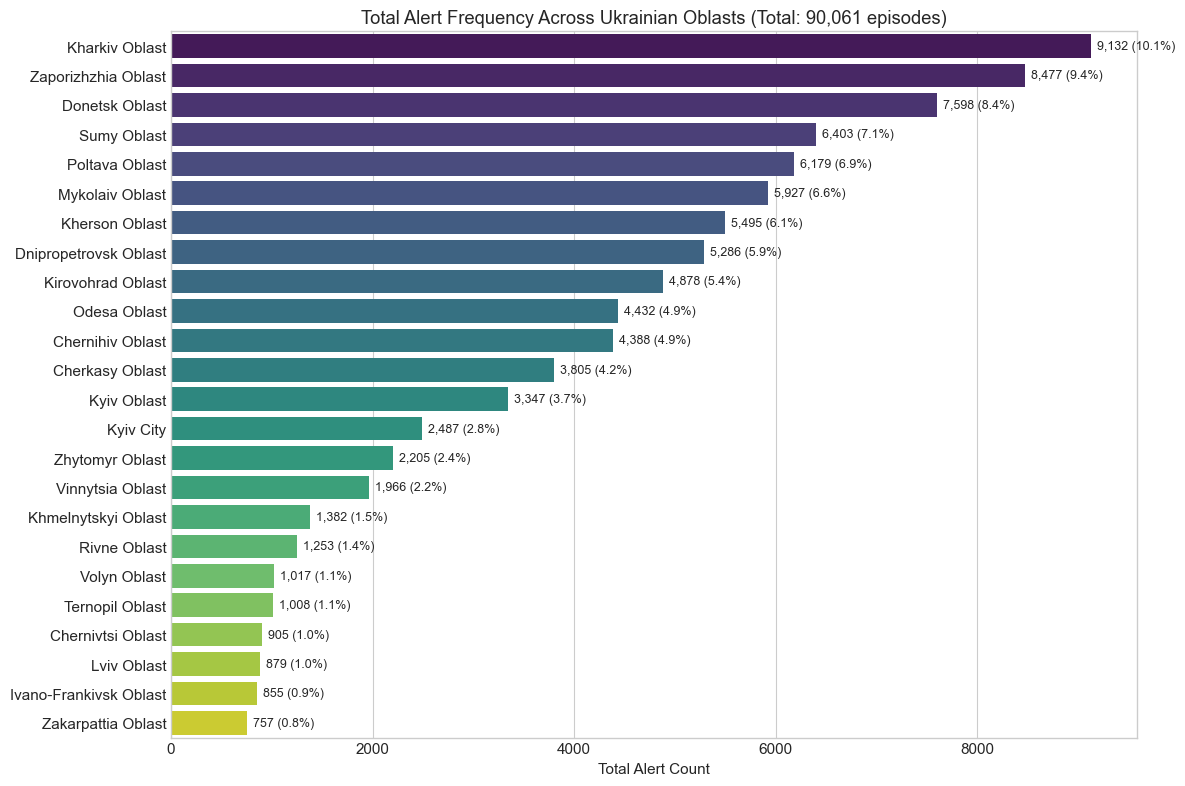

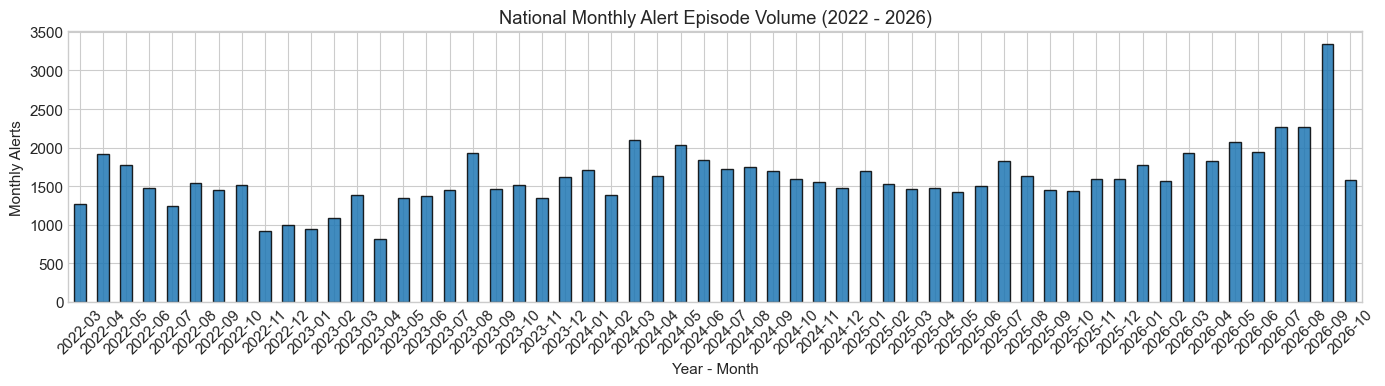

In [13]:
# 3.1 Alert Frequency Analysis by Oblast
total_days = (df_alerts['started_at'].max() - df_alerts['started_at'].min()).total_seconds() / (24 * 3600)
months_approx = total_days / 30.4375

freq_stats = df_alerts.groupby('region_en').size().reset_index(name='total_alerts')
freq_stats['alerts_per_month'] = freq_stats['total_alerts'] / months_approx
freq_stats['alerts_per_week'] = freq_stats['total_alerts'] / (total_days / 7.0)
freq_stats['pct_national'] = 100.0 * freq_stats['total_alerts'] / len(df_alerts)
freq_stats = freq_stats.sort_values(by='total_alerts', ascending=False).reset_index(drop=True)

display(freq_stats)

# Plot Horizontal Bar Chart of Alert Frequency
plt.figure(figsize=(12, 8))
sns.barplot(
    data=freq_stats,
    y='region_en',
    x='total_alerts',
    palette='viridis'
)
plt.title(f"Total Alert Frequency Across Ukrainian Oblasts (Total: {len(df_alerts):,} episodes)")
plt.xlabel("Total Alert Count")
plt.ylabel("")
for i, v in enumerate(freq_stats['total_alerts']):
    plt.text(v + 60, i, f"{v:,} ({freq_stats['pct_national'].iloc[i]:.1f}%)", va='center', fontsize=9)
plt.tight_layout()
plt.show()

# Monthly Timeline of Nationwide Alert Counts
df_alerts['year_month'] = df_alerts['started_at'].dt.to_period('M').astype(str)
monthly_counts = df_alerts.groupby('year_month').size()

plt.figure(figsize=(14, 4))
monthly_counts.plot(kind='bar', color='#1f77b4', edgecolor='black', alpha=0.85)
plt.title("National Monthly Alert Episode Volume (2022 - 2026)")
plt.xlabel("Year - Month")
plt.ylabel("Monthly Alerts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,count,mean_min,median_min,std_min,p10_min,p90_min,iqr_min,max_hours
region_en,,,,,,,,
Dnipropetrovsk Oblast,5286,293.33,65.93,499.57,18.52,835.17,400.73,71.50
Donetsk Oblast,7598,161.18,61.98,282.02,19.03,372.13,137.92,69.28
Sumy Oblast,6403,147.79,69.03,206.01,19.87,357.27,144.05,43.36
Chernihiv Oblast,4388,147.69,64.16,207.68,18.77,387.53,142.93,34.19
Kharkiv Oblast,9132,111.58,47.63,171.41,17.42,273.64,87.65,36.88
Kyiv Oblast,3347,100.63,50.12,130.77,15.73,251.02,91.77,19.18
Zaporizhzhia Oblast,8477,94.14,44.98,143.13,17.91,215.36,65.10,22.69
Zhytomyr Oblast,2205,90.90,51.83,105.40,17.32,207.53,83.11,17.59
Poltava Oblast,6179,84.99,38.47,121.67,16.35,201.96,62.08,19.67


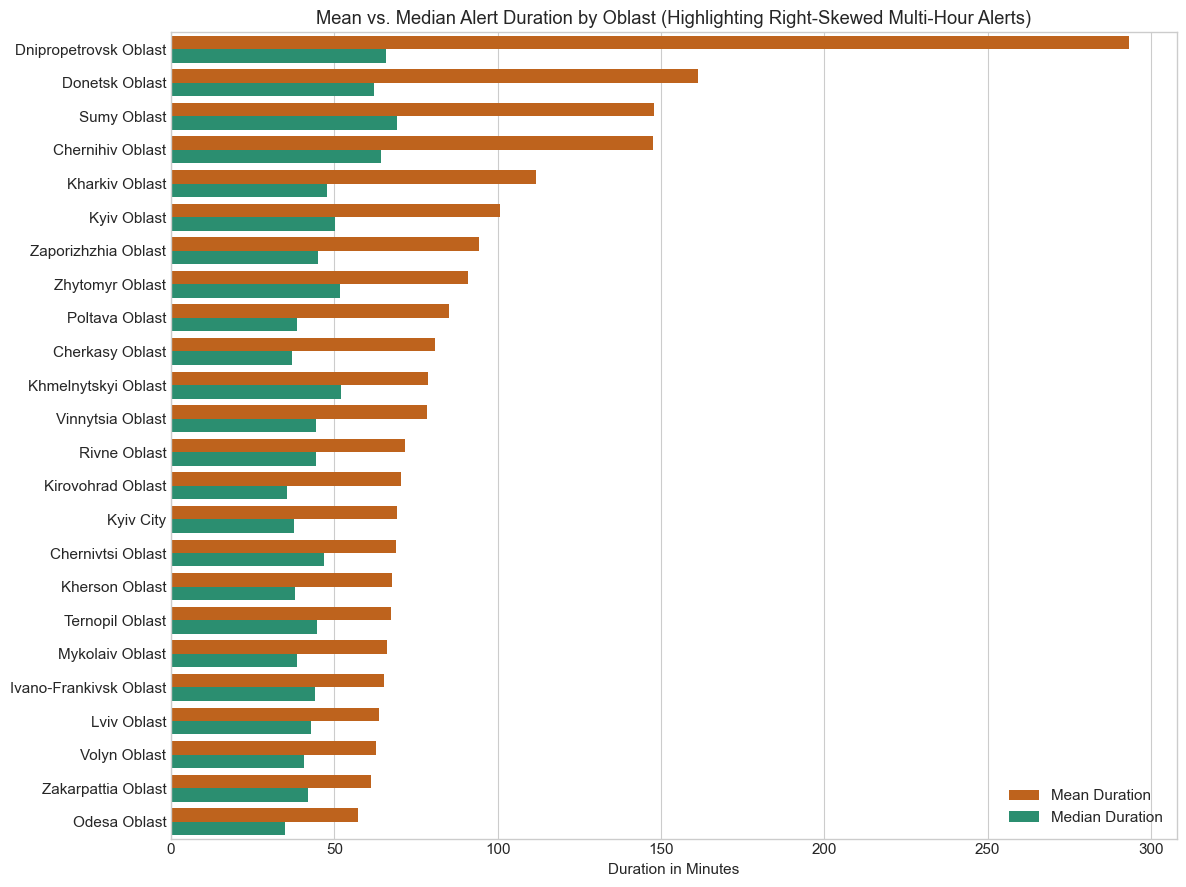

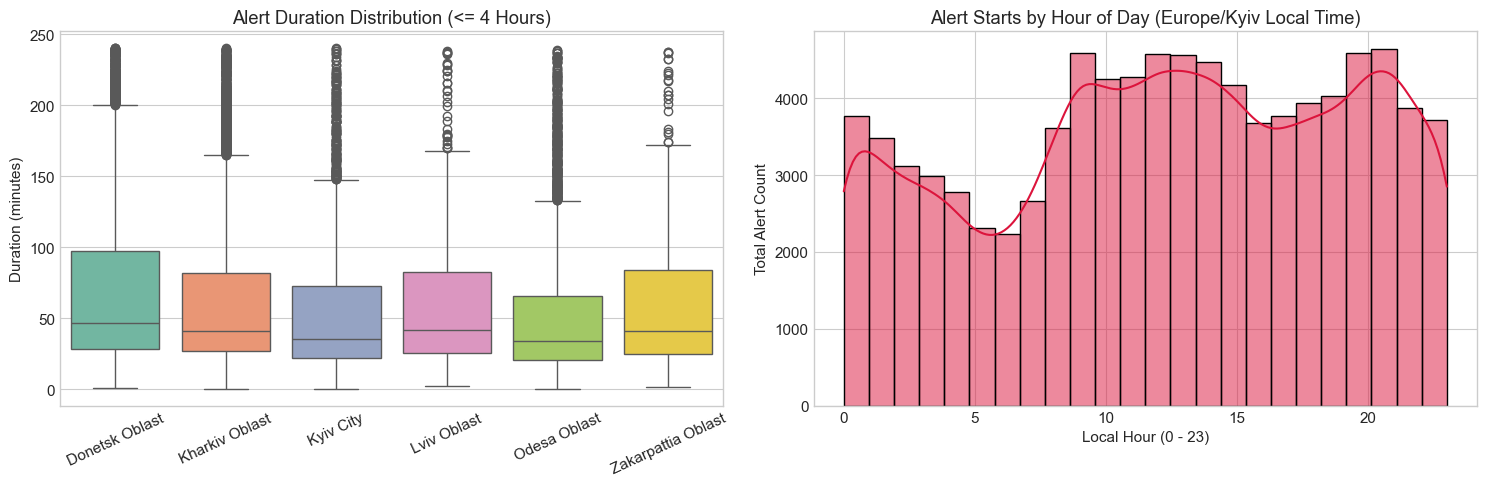

In [14]:
# 3.2 Duration Analysis: Mean vs. Median & Dispersion
duration_stats = df_alerts.groupby('region_en')['duration_min'].agg(
    count='count',
    mean_min='mean',
    median_min='median',
    std_min='std',
    p10_min=lambda s: np.percentile(s, 10),
    p90_min=lambda s: np.percentile(s, 90),
    iqr_min=lambda s: np.percentile(s, 75) - np.percentile(s, 25),
    max_hours=lambda s: s.max() / 60.0
).sort_values(by='mean_min', ascending=False)

display(duration_stats.round(2))

# Side-by-Side Comparison: Mean vs. Median Duration
dur_plot_df = duration_stats.reset_index().melt(
    id_vars='region_en',
    value_vars=['mean_min', 'median_min'],
    var_name='Metric',
    value_name='Duration (min)'
)
dur_plot_df['Metric'] = dur_plot_df['Metric'].map({'mean_min': 'Mean Duration', 'median_min': 'Median Duration'})

plt.figure(figsize=(12, 9))
sns.barplot(
    data=dur_plot_df,
    y='region_en',
    x='Duration (min)',
    hue='Metric',
    palette=['#d95f02', '#1b9e77']
)
plt.title("Mean vs. Median Alert Duration by Oblast (Highlighting Right-Skewed Multi-Hour Alerts)")
plt.xlabel("Duration in Minutes")
plt.ylabel("")
plt.legend(title="")
plt.tight_layout()
plt.show()

# Boxplot across Macro-Regions & Diurnal Hour-of-Day Pattern
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sample_regions = ['Donetsk Oblast', 'Kharkiv Oblast', 'Kyiv City', 'Odesa Oblast', 'Lviv Oblast', 'Zakarpattia Oblast']
sns.boxplot(
    data=df_alerts[df_alerts['region_en'].isin(sample_regions) & (df_alerts['duration_min'] <= 240)],
    x='region_en',
    y='duration_min',
    palette='Set2',
    ax=axes[0]
)
axes[0].set_title("Alert Duration Distribution (<= 4 Hours)")
axes[0].set_ylabel("Duration (minutes)")
axes[0].set_xlabel("")
axes[0].tick_params(axis='x', rotation=25)

# Diurnal Pattern (Hour of Day in Europe/Kyiv Local Time)
df_alerts['start_kyiv_hour'] = df_alerts['started_at'].dt.tz_convert('Europe/Kyiv').dt.hour
sns.histplot(df_alerts['start_kyiv_hour'], bins=24, kde=True, color='crimson', ax=axes[1])
axes[1].set_title("Alert Starts by Hour of Day (Europe/Kyiv Local Time)")
axes[1].set_xlabel("Local Hour (0 - 23)")
axes[1].set_ylabel("Total Alert Count")
plt.tight_layout()
plt.show()


,region_en,active_hours,co_active_neighbor_hours,pct_neighbor_simultaneous,neighbor_count
0,Poltava Oblast,14116,14101,99.893738,7
1,Chernivtsi Oblast,1920,1915,99.739583,4
2,Kirovohrad Oblast,10113,10056,99.436369,6
3,Ivano-Frankivsk Oblast,1765,1755,99.433428,4
4,Ternopil Oblast,2117,2105,99.433160,5
5,Zakarpattia Oblast,1512,1503,99.404762,2
6,Vinnytsia Oblast,4440,4408,99.279279,7
7,Cherkasy Oblast,8606,8542,99.256333,4
8,Kyiv Oblast,8613,8537,99.117613,6
9,Rivne Oblast,2707,2679,98.965645,4


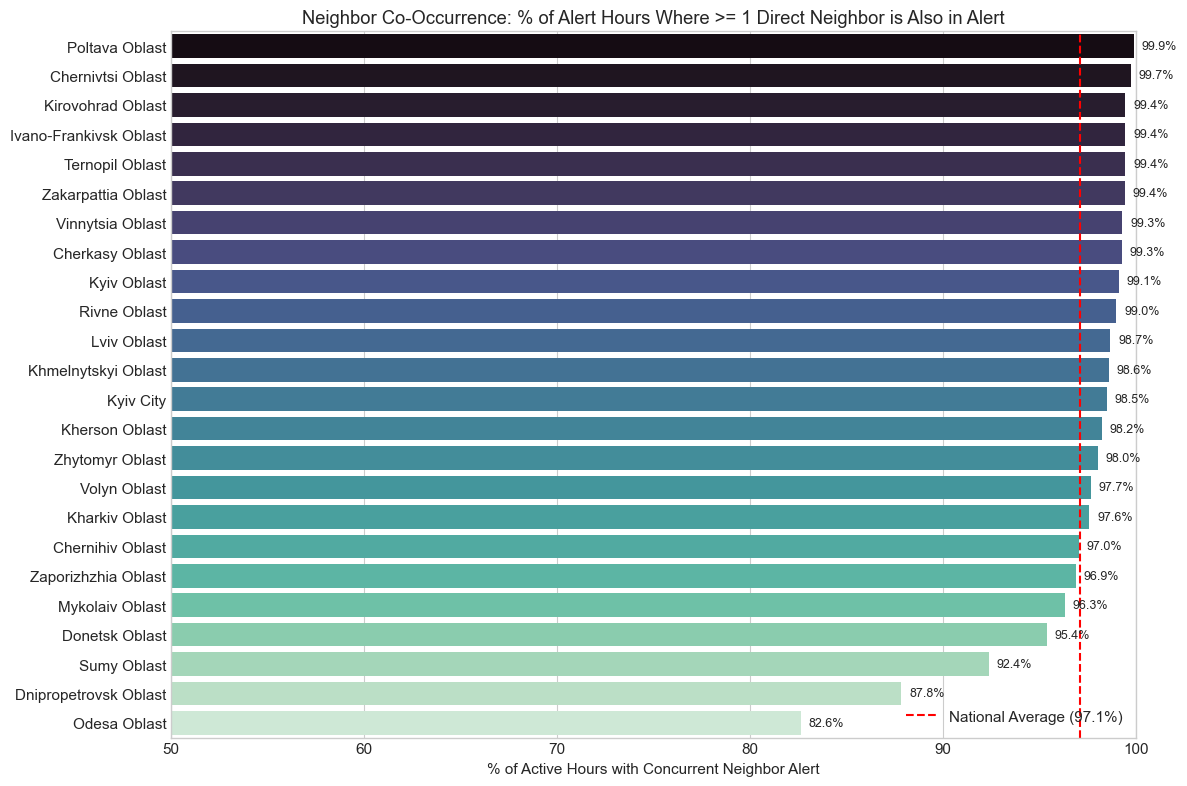

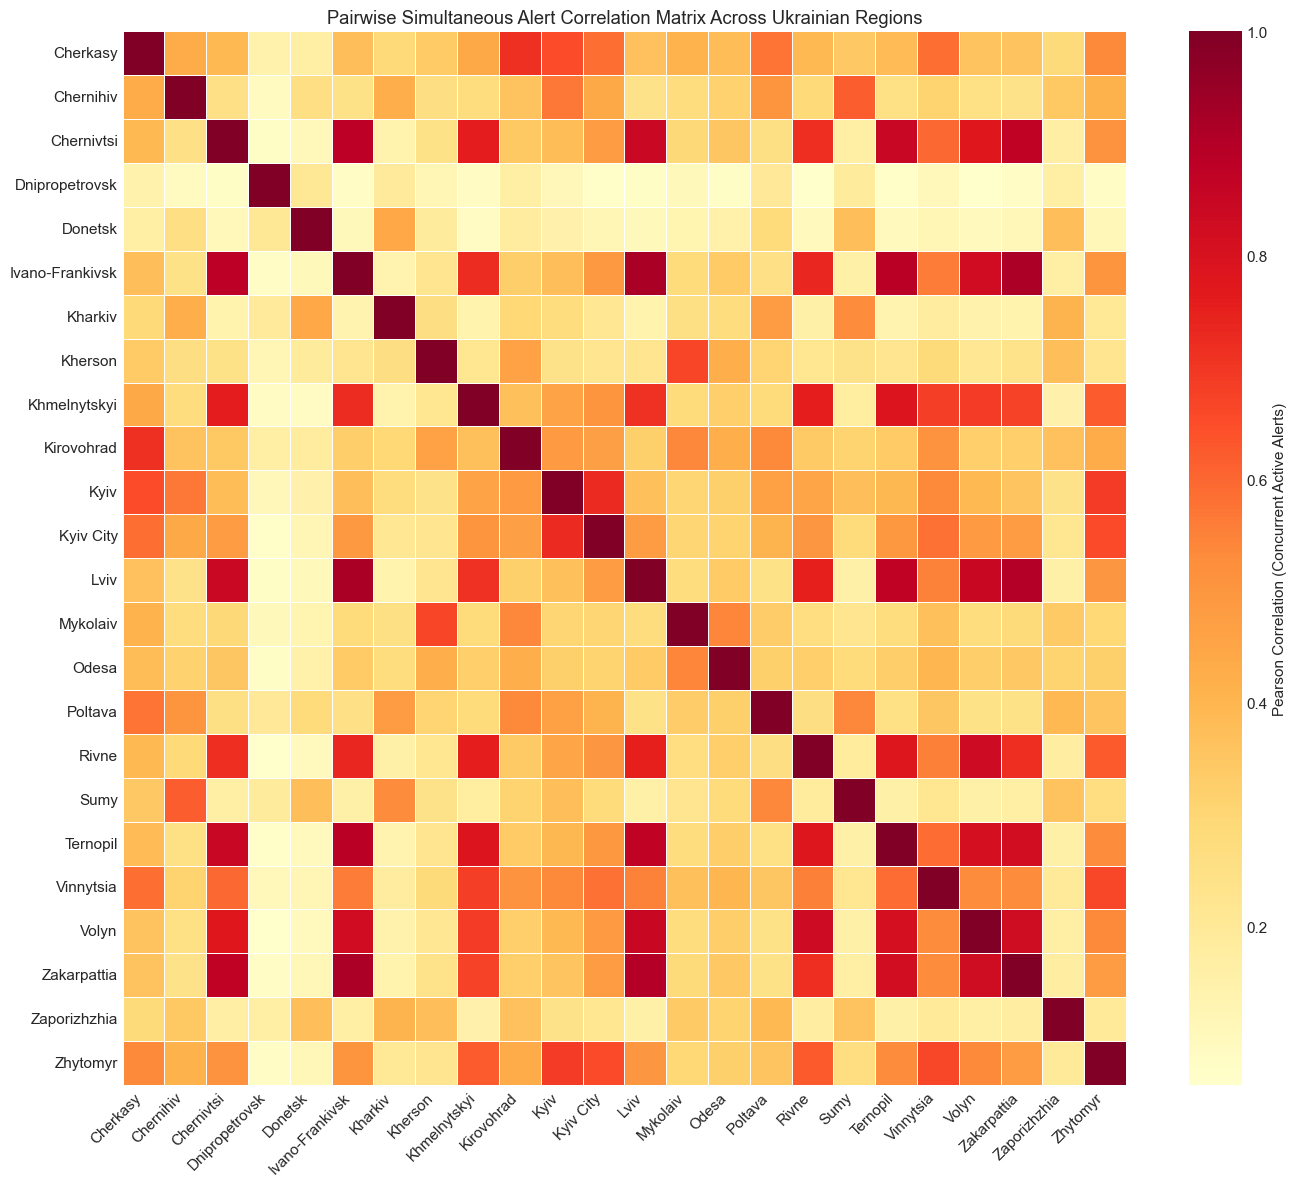

In [15]:
# 3.3 Spatial Context: Simultaneous Alerts in Neighboring Oblasts
start_time = df_alerts['started_at'].min().floor('h')
end_time = df_alerts['finished_at'].max().ceil('h')
hourly_grid = pd.date_range(start_time, end_time, freq='1h', tz='UTC')

region_ids = sorted(df_alerts['region_id'].unique())
reg_to_idx = {r: i for i, r in enumerate(region_ids)}
matrix = np.zeros((len(hourly_grid), len(region_ids)), dtype=bool)

for _, row in df_alerts.iterrows():
    c = reg_to_idx[row['region_id']]
    s_idx = max(0, int((row['started_at'] - start_time).total_seconds() // 3600))
    e_idx = min(len(hourly_grid), int((row['finished_at'] - start_time).total_seconds() // 3600) + 1)
    matrix[s_idx:e_idx, c] = True

# Compute Simultaneous Alert Percentage with Direct Neighbors
neighbor_sim_results = []
for reg in region_ids:
    c = reg_to_idx[reg]
    reg_active = matrix[:, c]
    total_active_hours = int(reg_active.sum())
    
    direct_neighbors = [n for n in OBLAST_NEIGHBORS.get(reg, []) if n in reg_to_idx]
    if not direct_neighbors or total_active_hours == 0:
        continue
    
    n_indices = [reg_to_idx[n] for n in direct_neighbors]
    any_neighbor_active = matrix[:, n_indices].any(axis=1)
    co_active_hours = int((reg_active & any_neighbor_active).sum())
    
    reg_en = df_alerts[df_alerts['region_id'] == reg]['region_en'].iloc[0]
    
    neighbor_sim_results.append({
        'region_id': reg,
        'region_en': reg_en,
        'active_hours': total_active_hours,
        'co_active_neighbor_hours': co_active_hours,
        'pct_neighbor_simultaneous': 100.0 * co_active_hours / total_active_hours,
        'neighbor_count': len(direct_neighbors),
    })

df_neighbor_sim = pd.DataFrame(neighbor_sim_results).sort_values('pct_neighbor_simultaneous', ascending=False).reset_index(drop=True)
display(df_neighbor_sim[['region_en', 'active_hours', 'co_active_neighbor_hours', 'pct_neighbor_simultaneous', 'neighbor_count']])

# Bar Plot: Neighbor Co-Occurrence Percentage
plt.figure(figsize=(12, 8))
sns.barplot(
    data=df_neighbor_sim,
    y='region_en',
    x='pct_neighbor_simultaneous',
    palette='mako'
)
mean_sim = df_neighbor_sim['pct_neighbor_simultaneous'].mean()
plt.axvline(x=mean_sim, color='red', linestyle='--', label=f"National Average ({mean_sim:.1f}%)")
plt.title("Neighbor Co-Occurrence: % of Alert Hours Where >= 1 Direct Neighbor is Also in Alert")
plt.xlabel("% of Active Hours with Concurrent Neighbor Alert")
plt.ylabel("")
plt.xlim(50, 100)
plt.legend(loc='lower right')
for i, v in enumerate(df_neighbor_sim['pct_neighbor_simultaneous']):
    plt.text(v + 0.4, i, f"{v:.1f}%", va='center', fontsize=9)
plt.tight_layout()
plt.show()

# Pairwise Correlation Heatmap Across All 24 Regions
id_to_en = df_alerts.drop_duplicates('region_id').set_index('region_id')['region_en'].to_dict()
clean_names = [id_to_en.get(r, r).replace(' Oblast', '').replace(' Autonomous Republic of ', '') for r in region_ids]
df_hourly = pd.DataFrame(matrix.astype(int), columns=clean_names)
corr_matrix = df_hourly.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_matrix,
    cmap='YlOrRd',
    annot=False,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation (Concurrent Active Alerts)'}
)
plt.title("Pairwise Simultaneous Alert Correlation Matrix Across Ukrainian Regions")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


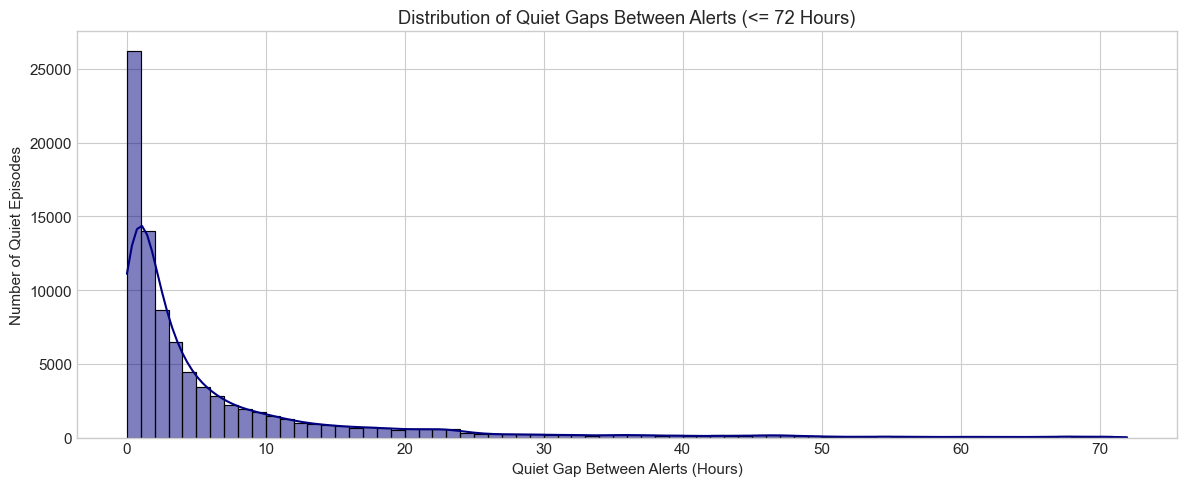

Median Quiet Hours Between Alerts by Oblast (Frontline vs. Rear Oblasts):


,region_en,episode_count,median_quiet_hours,p25_quiet_hours,p75_quiet_hours
0,Dnipropetrovsk Oblast,5284,1.082917,0.371250,2.652708
1,Kharkiv Oblast,9130,1.249028,0.410852,3.178958
2,Sumy Oblast,6402,1.321528,0.453542,3.662778
3,Donetsk Oblast,7597,1.381944,0.500278,3.035833
4,Zaporizhzhia Oblast,8476,1.800417,0.652431,4.210139
5,Chernihiv Oblast,4387,2.178143,0.707500,7.193333
6,Mykolaiv Oblast,5926,2.625556,0.880772,7.109583
7,Poltava Oblast,6178,2.693611,1.015833,6.614236
8,Kherson Oblast,5493,2.754167,1.009722,6.961389
9,Odesa Oblast,4431,3.327222,1.020693,9.796806


In [16]:
# 3.4 Inter-Alert Quiet Gap Distribution (Task B)
plt.figure(figsize=(12, 5))
gap_hours = df_gaps['gap_duration_min'] / 60.0

sns.histplot(gap_hours[gap_hours <= 72], bins=72, color='navy', kde=True)
plt.title("Distribution of Quiet Gaps Between Alerts (<= 72 Hours)")
plt.xlabel("Quiet Gap Between Alerts (Hours)")
plt.ylabel("Number of Quiet Episodes")
plt.tight_layout()
plt.show()

gap_summary = df_gaps.groupby('region_en')['gap_duration_min'].agg(
    episode_count='count',
    median_quiet_hours=lambda s: s.median() / 60.0,
    p25_quiet_hours=lambda s: np.percentile(s, 25) / 60.0,
    p75_quiet_hours=lambda s: np.percentile(s, 75) / 60.0,
).sort_values(by='median_quiet_hours').reset_index()

print("Median Quiet Hours Between Alerts by Oblast (Frontline vs. Rear Oblasts):")
display(gap_summary)


## 4. Chronological Train / Test Split
**PLAN.md Section 5.6:** *Never shuffle time series data.* We perform a strict point-in-time split (e.g. 80% train, 20% test on recent months) to prevent data leakage.


In [17]:
# Split alerts (Task A) and gaps (Task B)
alerts_train, alerts_test = create_time_split(df_alerts, timestamp_col='started_at', train_ratio=0.80)
gaps_train, gaps_test = create_time_split(df_gaps, timestamp_col='gap_start', train_ratio=0.80)

split_date = alerts_test['started_at'].min()
print(f"Train/Test split cutoff timestamp: {split_date}")
print(f"Task A (Alerts): Train = {len(alerts_train):,}, Test = {len(alerts_test):,}")
print(f"Task B (Gaps):   Train = {len(gaps_train):,}, Test = {len(gaps_test):,}")


Train/Test split cutoff timestamp: 2026-02-14 11:00:11+00:00
Task A (Alerts): Train = 72,048, Test = 18,013
Task B (Gaps):   Train = 72,024, Test = 18,006


## 5. Baseline Models (PLAN.md Section 5.1)
The core insight: When an alert has already lasted $t$ minutes, what is the conditional distribution of remaining time:
$$P(\text{remaining} \le \Delta \mid \text{duration} > t)$$
We implement:
1. **Empirical Conditional Quantile Baseline**: Non-parametric conditional quantiles ($P10, P50, P90$) and probabilities.
2. **Kaplan-Meier Survival Baseline**: Survival curve $S(t) = P(D > t)$ with conditional probability:
$$P(\text{ends within } \Delta \mid D > t) = 1 - \frac{S(t + \Delta)}{S(t)}$$


In [18]:
# 5.1 Fit Empirical Baseline on Training Data
baseline_empirical = EmpiricalConditionalBaseline().fit(alerts_train)

# Fit Kaplan-Meier baseline
km_baseline = KaplanMeierBaseline().fit(alerts_train)

# Compare predictions for Kyiv City when alert has lasted 30 minutes
pred_kyiv_30m = baseline_empirical.predict_remaining('kyiv_city', elapsed_min=30.0)
km_prob_30m_end_in_15m = km_baseline.predict_survival_prob('kyiv_city', elapsed_min=30.0, delta_min=15.0)

print("Empirical Baseline Prediction (Kyiv City, elapsed = 30m):")
print(f"  Predicted remaining median: {pred_kyiv_30m['p50']:.1f} min")
print(f"  Uncertainty range [P10, P90]: [{pred_kyiv_30m['p10']:.1f}, {pred_kyiv_30m['p90']:.1f}] min")
print(f"  Probability ends within 15 min: {pred_kyiv_30m['probabilities']['within_15m']:.1%}")
print(f"  Kaplan-Meier prob ends within 15 min: {km_prob_30m_end_in_15m:.1%}")


Empirical Baseline Prediction (Kyiv City, elapsed = 30m):
  Predicted remaining median: 38.1 min
  Uncertainty range [P10, P90]: [3.4, 184.8] min
  Probability ends within 15 min: 30.3%
  Kaplan-Meier prob ends within 15 min: 30.3%


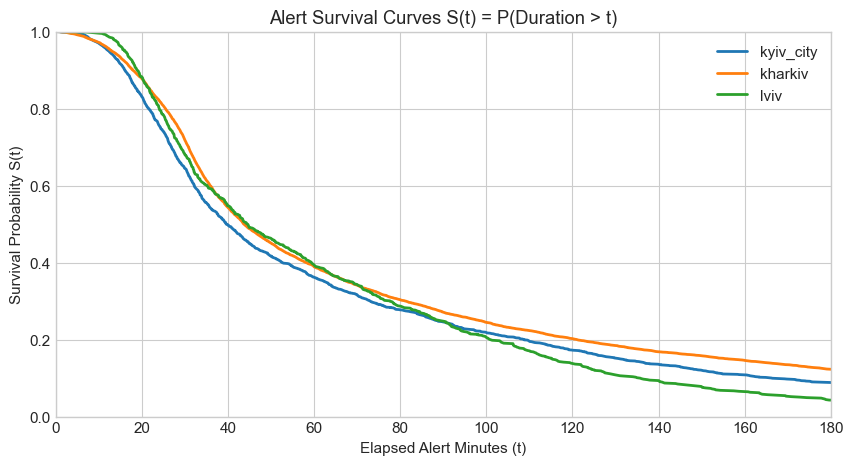

In [19]:
# 5.2 Plot Kaplan-Meier Survival Curves for Selected Regions
plt.figure(figsize=(10, 5))
for reg_id in ['kyiv_city', 'kharkiv', 'lviv']:
    kmf = km_baseline.kmfs[reg_id]
    plt.plot(kmf.survival_function_.index, kmf.survival_function_['KM_estimate'], label=reg_id, lw=2)

plt.title("Alert Survival Curves S(t) = P(Duration > t)")
plt.xlabel("Elapsed Alert Minutes (t)")
plt.ylabel("Survival Probability S(t)")
plt.xlim(0, 180)
plt.ylim(0, 1)
plt.legend()
plt.show()


## 6. Feature Engineering & As-Of Moment Sampling
**PLAN.md Section 5.6:** In production, users query the app at arbitrary moments *during* an ongoing alert.
To train models accurately:
- We sample "as-of" snapshot moments $t \in [0, 5, 10, 15, 20, 30, 45, 60, 90, 120]$ inside each historical alert episode.
- At snapshot $t$:
  - Feature: $elapsed\_min = t$
  - Target: $remaining\_min = \text{total duration} - t$
  - Classification Targets: $ends\_within\_15m, ends\_within\_30m, ends\_within\_60m$
- We compute point-in-time cyclical time features (hour sine/cosine, weekday, month, weekend).


In [20]:
# Sample as-of snapshots for Task A
train_a_samples = sample_as_of_alert_moments(alerts_train)
test_a_samples = sample_as_of_alert_moments(alerts_test)

# Sample as-of snapshots for Task B
train_b_samples = sample_as_of_gap_moments(gaps_train)
test_b_samples = sample_as_of_gap_moments(gaps_test)

print(f"Task A (Alert Duration) Snapshots -> Train: {len(train_a_samples):,}, Test: {len(test_a_samples):,}")
print(f"Task B (Quiet Gaps) Snapshots     -> Train: {len(train_b_samples):,}, Test: {len(test_b_samples):,}")
display(train_a_samples.head())


Task A (Alert Duration) Snapshots -> Train: 494,545, Test: 122,897
Task B (Quiet Gaps) Snapshots     -> Train: 303,993, Test: 53,275


,region_id,region_en,as_of_ts,start_ts,elapsed_min,total_duration_min,target_remaining_min,target_ends_within_15m,target_ends_within_30m,target_ends_within_60m,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,month
0,vinnytsia,Vinnytsia Oblast,2022-03-15 16:10:34+00:00,2022-03-15 16:10:34+00:00,0.0,39.55,39.55,0,0,1,-0.887011,-0.461749,0.781831,0.62349,0,3
1,vinnytsia,Vinnytsia Oblast,2022-03-15 16:15:34+00:00,2022-03-15 16:10:34+00:00,5.0,39.55,34.55,0,0,1,-0.896873,-0.442289,0.781831,0.62349,0,3
2,vinnytsia,Vinnytsia Oblast,2022-03-15 16:20:34+00:00,2022-03-15 16:10:34+00:00,10.0,39.55,29.55,0,1,1,-0.906308,-0.422618,0.781831,0.62349,0,3
3,vinnytsia,Vinnytsia Oblast,2022-03-15 16:25:34+00:00,2022-03-15 16:10:34+00:00,15.0,39.55,24.55,0,1,1,-0.915311,-0.402747,0.781831,0.62349,0,3
4,vinnytsia,Vinnytsia Oblast,2022-03-15 16:30:34+00:00,2022-03-15 16:10:34+00:00,20.0,39.55,19.55,0,1,1,-0.923880,-0.382683,0.781831,0.62349,0,3


### 6.1 Neighbor-Region Context (notebooks/03_neighbor_features.ipynb)
`AlertPredictionPipeline`'s quantile models also take point-in-time
neighbor-activity features (see that notebook for the comparison that
justified adding them): for each as-of moment, how many of a region's
direct neighbors - and how many regions nationally - were active at that
exact historical moment, via a leakage-safe backward as-of join.


In [21]:
from alertpred.config import OBLAST_NEIGHBORS
from alertpred.features.builder import compute_neighbor_active_features

train_a_samples = compute_neighbor_active_features(train_a_samples, df_alerts, OBLAST_NEIGHBORS)
test_a_samples = compute_neighbor_active_features(test_a_samples, df_alerts, OBLAST_NEIGHBORS)
train_b_samples = compute_neighbor_active_features(train_b_samples, df_alerts, OBLAST_NEIGHBORS)
test_b_samples = compute_neighbor_active_features(test_b_samples, df_alerts, OBLAST_NEIGHBORS)
print("Neighbor context features attached.")


Neighbor context features attached.


## 7. Machine Learning Models: LightGBM Quantile & Probability
We train:
1. **LightGBM Quantile Regressors** with $\alpha \in [0.10, 0.50, 0.90]$ to predict remaining duration and intervals.
2. **LightGBM Binary Classifiers** to output calibrated probabilities:
   - Task A: $P(\text{ends within } 15, 30, 60 \text{ min})$
   - Task B: $P(\text{starts within } 1, 3, 6 \text{ hours})$


In [22]:
# Initialize end-to-end pipeline
pipeline = AlertPredictionPipeline()

# Train Task A (Alert Remaining Duration)
print("--> Training Task A Models...")
pipeline.fit_task_a(train_a_samples)

# Train Task B (Quiet Gap Until Next Alert)
print("--> Training Task B Models...")
pipeline.fit_task_b(train_b_samples)

print("All models successfully trained!")


--> Training Task A Models...
Training Task A (Remaining alert duration quantiles P10/P50/P90)...


Training Task A (Probability of alert end within 15/30/60m)...


--> Training Task B Models...
Training Task B (Quiet gap until next alert quantiles P10/P50/P90)...


Training Task B (Probability of next alert within 1h/3h/6h)...


All models successfully trained!


## 8. Model Evaluation & Benchmark Comparison
Comparing **LightGBM** vs. **Empirical Baseline** on the held-out test split:
- **MAE / Median AE:** point accuracy in minutes
- **Pinball Loss:** quantile calibration
- **P10-P90 Coverage:** fraction of true outcomes inside the predicted interval (target: ~80%)
- **Brier Score & Accuracy:** probability calibration


In [23]:
# Evaluate Task A Baseline
baseline_preds = baseline_empirical.predict_batch(test_a_samples, elapsed_col='elapsed_min')
eval_baseline_a = evaluate_quantile_predictions(
    y_true=test_a_samples['target_remaining_min'].values,
    p10=baseline_preds['baseline_p10'].values,
    p50=baseline_preds['baseline_p50'].values,
    p90=baseline_preds['baseline_p90'].values
)

# Evaluate Task A LightGBM
lgb_preds_a = pipeline.task_a_quantile.predict(test_a_samples)
eval_lgb_a = evaluate_quantile_predictions(
    y_true=test_a_samples['target_remaining_min'].values,
    p10=lgb_preds_a['pred_p10'].values,
    p50=lgb_preds_a['pred_p50'].values,
    p90=lgb_preds_a['pred_p90'].values
)

# Benchmark Comparison Table
comparison_df = pd.DataFrame([
    {"Model": "Empirical Baseline", **eval_baseline_a},
    {"Model": "LightGBM Quantile", **eval_lgb_a},
])
display(comparison_df[['Model', 'mae_p50_min', 'median_ae_p50_min', 'coverage_p10_p90', 'mean_pinball_loss']])


,Model,mae_p50_min,median_ae_p50_min,coverage_p10_p90,mean_pinball_loss
0,Empirical Baseline,122.972265,35.141767,0.741239,44.479940
1,LightGBM Quantile,122.465445,40.447182,0.686176,44.983916


In [24]:
# Evaluate Probability Classifiers for Task A (Ends within 15/30/60 min)
lgb_probs_a = pipeline.task_a_probs.predict_proba(test_a_samples)
prob_evals = []
for h in [15, 30, 60]:
    metrics = evaluate_classification_probabilities(
        y_true_binary=test_a_samples[f'target_ends_within_{h}m'].values,
        y_prob=lgb_probs_a[f'prob_ends_within_{h}m'].values
    )
    metrics['Horizon'] = f"Ends within {h}m"
    prob_evals.append(metrics)

display(pd.DataFrame(prob_evals)[['Horizon', 'accuracy', 'brier_score', 'roc_auc']])


,Horizon,accuracy,brier_score,roc_auc
0,Ends within 15m,0.806456,0.153182,0.602599
1,Ends within 30m,0.612977,0.231936,0.601251
2,Ends within 60m,0.585279,0.252450,0.624060


## 9. Interactive Scenario Explorer
Simulating live queries that will appear in the Streamlit web app.


In [25]:
# 9.1 Scenario: Active Alert in Kyiv running for 35 minutes
pred_active_kyiv = pipeline.predict_active_alert(
    region_id='kyiv_city',
    elapsed_min=35.0,
    timestamp=pd.Timestamp.now(tz='UTC')
)

print("=" * 60)
print("SCENARIO 1: ACTIVE ALERT IN KYIV (Elapsed: 35 minutes)")
print("=" * 60)
print(f"Predicted Remaining Duration (Median P50): {pred_active_kyiv['predicted_remaining_median_min']} min")
print(f"Predicted Uncertainty Range [P10, P90]   : {pred_active_kyiv['predicted_range_p10_p90_min']} min")
print("Probabilities:")
for k, v in pred_active_kyiv['probabilities'].items():
    print(f"  • {k}: {v:.1%}")


SCENARIO 1: ACTIVE ALERT IN KYIV (Elapsed: 35 minutes)
Predicted Remaining Duration (Median P50): 18.1 min
Predicted Uncertainty Range [P10, P90]   : [1.4, 111.5] min
Probabilities:
  • prob_ends_within_15m: 37.6%
  • prob_ends_within_30m: 53.8%
  • prob_ends_within_60m: 71.3%


In [26]:
# 9.2 Scenario: Quiet Region in Lviv with no alert for 4 hours
pred_quiet_lviv = pipeline.predict_quiet_region(
    region_id='lviv',
    elapsed_quiet_min=240.0,
    prev_alert_duration_min=40.0,
    timestamp=pd.Timestamp.now(tz='UTC')
)

print("=" * 60)
print("SCENARIO 2: QUIET PERIOD IN LVIV (Quiet for: 4 hours)")
print("=" * 60)
print(f"Predicted Gap to Next Alert (Median P50): {pred_quiet_lviv['predicted_next_alert_gap_median_min']} min ({pred_quiet_lviv['predicted_next_alert_gap_median_min']/60:.1f} hrs)")
print(f"Predicted Uncertainty Range [P10, P90]  : {pred_quiet_lviv['predicted_range_p10_p90_min']} min")
print("Probabilities:")
for k, v in pred_quiet_lviv['probabilities'].items():
    print(f"  • {k}: {v:.1%}")


SCENARIO 2: QUIET PERIOD IN LVIV (Quiet for: 4 hours)
Predicted Gap to Next Alert (Median P50): 2179.9 min (36.3 hrs)
Predicted Uncertainty Range [P10, P90]  : [413.3, 5253.9] min
Probabilities:
  • prob_starts_within_1h: 2.6%
  • prob_starts_within_3h: 6.2%
  • prob_starts_within_6h: 8.5%


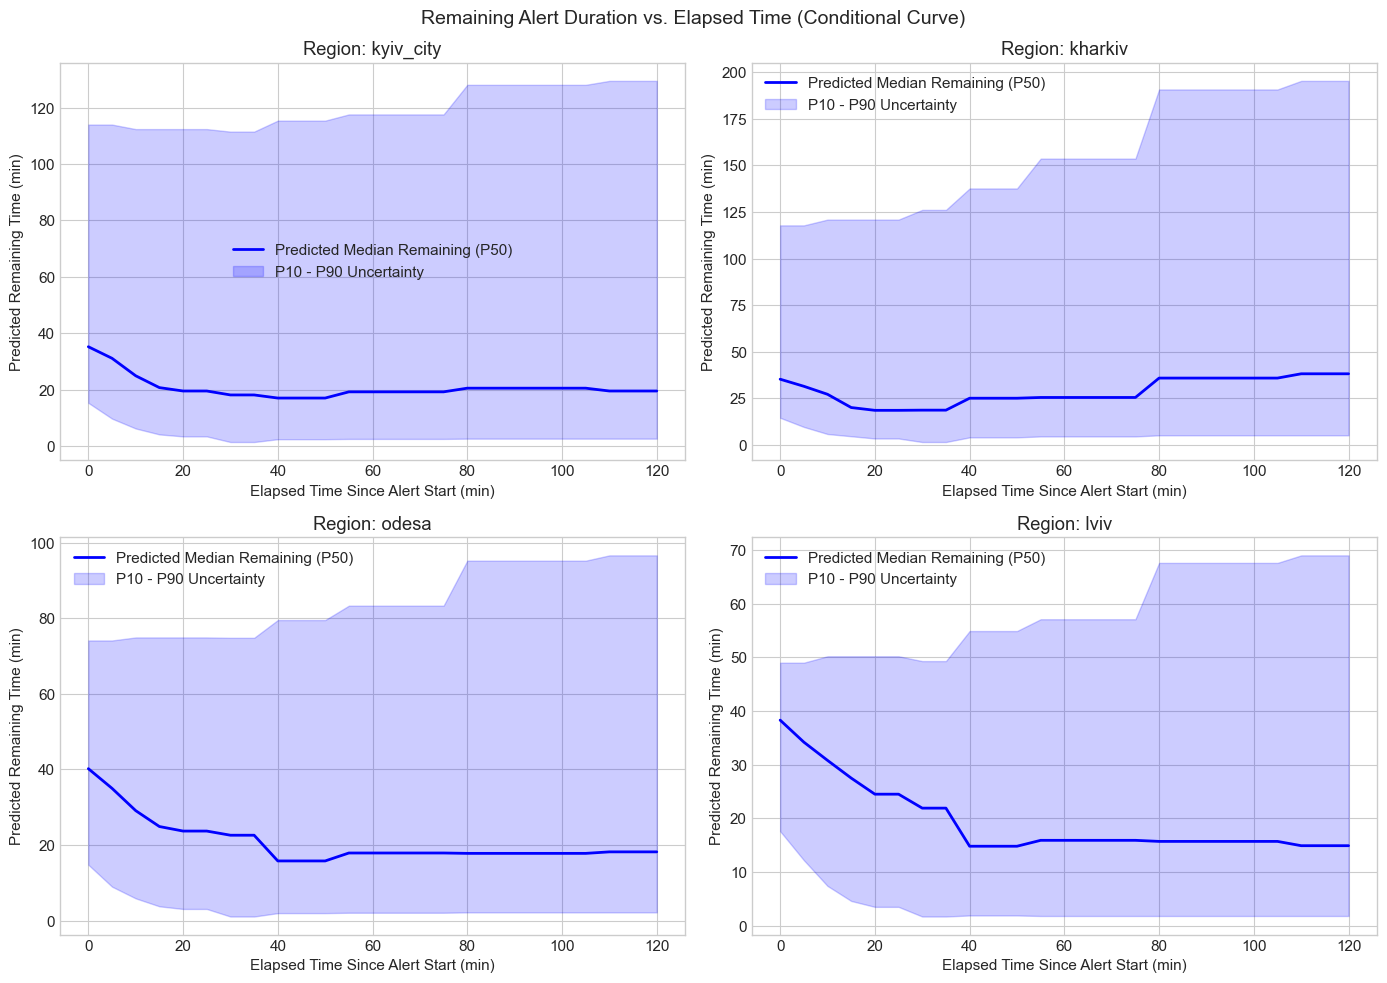

In [27]:
# 9.3 Visualizing Predicted Remaining Duration vs. Elapsed Time for Multiple Oblasts
elapsed_grid = np.linspace(0, 120, 25)
regions_to_plot = ['kyiv_city', 'kharkiv', 'odesa', 'lviv']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, reg in enumerate(regions_to_plot):
    p50_list, p10_list, p90_list = [], [], []
    for t in elapsed_grid:
        res = pipeline.predict_active_alert(reg, elapsed_min=t)
        p50_list.append(res['predicted_remaining_median_min'])
        p10_list.append(res['predicted_range_p10_p90_min'][0])
        p90_list.append(res['predicted_range_p10_p90_min'][1])
        
    ax = axes[idx]
    ax.plot(elapsed_grid, p50_list, 'b-', label='Predicted Median Remaining (P50)', lw=2)
    ax.fill_between(elapsed_grid, p10_list, p90_list, color='blue', alpha=0.2, label='P10 - P90 Uncertainty')
    ax.set_title(f"Region: {reg}")
    ax.set_xlabel("Elapsed Time Since Alert Start (min)")
    ax.set_ylabel("Predicted Remaining Time (min)")
    ax.legend()
    
plt.suptitle("Remaining Alert Duration vs. Elapsed Time (Conditional Curve)", fontsize=14)
plt.tight_layout()
plt.show()


## 10. Model Serialization & Export
Saving the trained pipeline artifact to `models/` directory for direct integration into the main project app.


In [28]:
# Save the trained pipeline
saved_path = pipeline.save(MODELS_DIR / "alertpred_pipeline.joblib")
print(f"Pipeline artifact saved to: {saved_path}")

# Verify deserialization
loaded_pipeline = AlertPredictionPipeline.load(saved_path)
test_pred = loaded_pipeline.predict_active_alert('kyiv_city', elapsed_min=15.0)
print("Reloaded pipeline test prediction successful!")
print(test_pred)


Saved pipeline artifacts to: /Users/allakovalcuk/Agentic_AI/models/alertpred_pipeline.joblib
Pipeline artifact saved to: /Users/allakovalcuk/Agentic_AI/models/alertpred_pipeline.joblib
Reloaded pipeline test prediction successful!
{'task': 'A_active_alert', 'region_id': 'kyiv_city', 'elapsed_min': 15.0, 'predicted_remaining_median_min': 20.7, 'predicted_range_p10_p90_min': [4.1, 112.4], 'probabilities': {'prob_ends_within_15m': 0.338, 'prob_ends_within_30m': 0.562, 'prob_ends_within_60m': 0.712}}
